# Lab 06: Object Detection with YOLO (Traffic and Mask-Wearing Datasets). #

* **Student:** Truong Ngoc Gia Hieu - 105565520
* **Unit:** Applied Machine Learning (COS30082) - Swinburne University of Technology
* **Task:** Evaluate a pretrained YOLO model, fine-tune it on my own datasets, compare both, then select the best model size and check the 80% target.
* **Data source:** Google Drive -> `Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/Traffic Dataset`. This folder contains two YOLO-format datasets:
    * **Traffic** (`images/` + `labels/`): traffic scenes, several classes, splits `train / val / test`.
    * **Mask** (`train/`, `valid/`, `test/` + `data.yaml`): Roboflow *mask-wearing* dataset, 2 classes (`mask`, `no-mask`), public domain licence (https://universe.roboflow.com/joseph-nelson/mask-wearing/dataset/1).
* **Implementation:** Ultralytics YOLO (https://docs.ultralytics.com/).
* **Target:** mAP50, mAP50-95, precision and recall all >= 0.80.

**Notebook structure:** Part A (Dataset Loading) -> Part B (EDA) -> Part C (Pretrained Model) -> Part D (Fine-Tuning) -> Part E (Evaluation and Comparison) -> Part F (Model Selection and Optimisation) -> Part G (Conclusions).

> **Runtime:** use a GPU runtime in Colab (Runtime -> Change runtime type -> T4 GPU) before running Part C onwards.

# Part A: Dataset Loading. #

In this part I install the YOLO library, mount Google Drive, copy both datasets to the Colab disk, check their folder structure, and create one `data.yaml` file for each dataset.

## 1.1 Install Library and Mount Google Drive. ##

In [ ]:
#-- Install Ultralytics (the YOLO implementation used in this lab). --#
!pip install -q ultralytics

In [ ]:
#-- Import Libraries. --#
import os
import time
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from collections import Counter
from google.colab import drive

#-- Mount Google Drive. --#
drive.mount('/content/drive')

#-- Path of the dataset folder on Google Drive (same style as Lab05). --#
drive_lab_dir = '/content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/'
drive_dataset_dir = os.path.join(drive_lab_dir, 'Traffic Dataset')

#-- Fix the random seed so the random samples shown in this notebook are reproducible. --#
random.seed(42)
np.random.seed(42)

Mounted at /content/drive


In [ ]:
#-- Check the GPU is available (training on CPU is very slow). --#
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


## 1.2 Check the Dataset Folder Structure. ##

In [ ]:
#-- Check the dataset folder exists or not, then list what is inside. --#
if os.path.exists(drive_dataset_dir):
    print(f"{drive_dataset_dir} exists")
    print(f"Content: {sorted(os.listdir(drive_dataset_dir))}")
else:
    print(f"{drive_dataset_dir} does not exist. Please check the path again.")

/content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/Traffic Dataset exists
Content: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'images', 'labels', 'test', 'train', 'valid']


In [ ]:
#-- Copy the datasets from Google Drive to the local Colab disk. --#
#-- Reading thousands of small files from Drive is slow, so training from the local disk is much faster. --#
#-- It also stops YOLO from writing its label cache files into my Drive folder. --#
data_root = '/content/Lab06_Data'
if os.path.exists(data_root):
    print(f"{data_root} already exists, skip copying.")
else:
    shutil.copytree(drive_dataset_dir, data_root)
    print(f"Datasets copied to {data_root}")
print(f"Content: {sorted(os.listdir(data_root))}")

#-- Folder where all YOLO runs are saved, and the folder on Drive where the final weights are kept. --#
RUNS_DIR = '/content/runs'
drive_models_dir = os.path.join(drive_lab_dir, 'models')
os.makedirs(drive_models_dir, exist_ok=True)

Datasets copied to /content/Lab06_Data
Content: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'images', 'labels', 'test', 'train', 'valid']


## 1.3 Describe the Two Datasets. ##

The two datasets use a different folder layout, so I describe where the images and labels of each split are. YOLO finds the label of an image by replacing `/images/` with `/labels/` in the image path, so both layouts work without moving any file.

In [ ]:
#-- Configuration of the two datasets. --#
DATASETS = {
    'Traffic': {
        'img_pattern': 'images/{folder}',                          #-- images/train, images/val, images/test --#
        'lbl_pattern': 'labels/{folder}',                          #-- labels/train, labels/val --#
        'folders': {'train': 'train', 'val': 'val', 'test': 'test'},
        'eval_split': 'val',                                       #-- the Traffic test images have no labels (see 1.4) --#
        'names': [],                                               #-- no names file: filled in section 1.5 --#
    },
    'Mask': {
        'img_pattern': '{folder}/images',                          #-- train/images, valid/images, test/images --#
        'lbl_pattern': '{folder}/labels',
        'folders': {'train': 'train', 'val': 'valid', 'test': 'test'},
        'eval_split': 'test',                                      #-- the Mask test set has labels, as the lab requires --#
        'names': ['mask', 'no-mask'],                              #-- taken from the Roboflow data.yaml --#
    },
}
SPLITS = ['train', 'val', 'test']
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

#-- Helper functions: folder of images / labels of one split, and the files inside. --#
def img_dir(ds, split):
    cfg = DATASETS[ds]
    return os.path.join(data_root, cfg['img_pattern'].format(folder=cfg['folders'][split]))

def lbl_dir(ds, split):
    cfg = DATASETS[ds]
    return os.path.join(data_root, cfg['lbl_pattern'].format(folder=cfg['folders'][split]))

def list_images(ds, split):
    folder = img_dir(ds, split)
    return sorted([f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)]) if os.path.isdir(folder) else []

def list_labels(ds, split):
    folder = lbl_dir(ds, split)
    return sorted([f for f in os.listdir(folder) if f.lower().endswith('.txt')]) if os.path.isdir(folder) else []

def labelled_splits(ds):
    #-- Splits that have label files (only these can give mAP, precision and recall). --#
    return [s for s in SPLITS if len(list_labels(ds, s)) > 0]

## 1.4 Count Images and Label Files in Each Split. ##

A YOLO dataset keeps one `.txt` label file for every image. A split with images but no label files cannot be used to calculate mAP, precision or recall.

In [ ]:
#-- Count the images and the label files of every split of both datasets. --#
rows = []
for ds in DATASETS:
    for split in SPLITS:
        rows.append({'Dataset': ds, 'Split': split,
                     'Images': len(list_images(ds, split)),
                     'Label files': len(list_labels(ds, split))})
summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

#-- Which splits can be evaluated. --#
for ds in DATASETS:
    print(f"\n{ds}: splits with labels = {labelled_splits(ds)}  |  evaluation split used = '{DATASETS[ds]['eval_split']}'")
    assert DATASETS[ds]['eval_split'] in labelled_splits(ds), f"The evaluation split of {ds} has no labels!"

Dataset Split  Images  Label files
Traffic train     738          738
Traffic   val     185          185
Traffic  test     260            0
   Mask train     104          104
   Mask   val      28           28
   Mask  test      15           15

Traffic: splits with labels = ['train', 'val']  |  evaluation split used = 'val'

Mask: splits with labels = ['train', 'val', 'test']  |  evaluation split used = 'test'


## 1.5 Create the data.yaml Files. ##

YOLO needs a `data.yaml` file with the split folders, the number of classes and the class names. For the Traffic dataset there is no names file, so the number of classes is found from the label files (highest class id + 1).

In [ ]:
#-- Find the number of classes of the Traffic dataset from its label files. --#
def find_class_ids(ds):
    ids = set()
    for split in SPLITS:
        for label_file in list_labels(ds, split):
            with open(os.path.join(lbl_dir(ds, split), label_file)) as fh:
                for line in fh:
                    parts = line.split()
                    if len(parts) > 0:
                        ids.add(int(parts[0]))
    return ids

for ds in DATASETS:
    ids = find_class_ids(ds)
    num_classes = max(ids) + 1
    print(f"{ds}: class ids found = {sorted(ids)} -> {num_classes} classes")
    names = DATASETS[ds]['names']
    if len(names) != num_classes:
        #-- Replace the list in DATASETS['Traffic']['names'] above with the real names if you know them. --#
        print(f"   names missing or wrong length -> using class_0, class_1, ... for {ds}")
        names = [f'class_{i}' for i in range(num_classes)]
    DATASETS[ds]['names'] = names
    DATASETS[ds]['nc'] = num_classes
    print(f"   class names: {names}")

Traffic: class ids found = [0, 1, 2, 3, 4, 5, 6] -> 7 classes
   names missing or wrong length -> using class_0, class_1, ... for Traffic
   class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4', 'class_5', 'class_6']
Mask: class ids found = [0, 1] -> 2 classes
   class names: ['mask', 'no-mask']


In [ ]:
#-- Write one data.yaml per dataset (YOLO reads the split folders relative to 'path'). --#
for ds, cfg in DATASETS.items():
    yaml_path = os.path.join(data_root, f'{ds.lower()}_data.yaml')
    with open(yaml_path, 'w') as f:
        f.write(f"path: {data_root}\n")
        f.write(f"train: {cfg['img_pattern'].format(folder=cfg['folders']['train'])}\n")
        f.write(f"val: {cfg['img_pattern'].format(folder=cfg['folders']['val'])}\n")
        #-- Only add the test split when it has labels. --#
        if 'test' in labelled_splits(ds):
            f.write(f"test: {cfg['img_pattern'].format(folder=cfg['folders']['test'])}\n")
        f.write(f"nc: {cfg['nc']}\n")
        f.write("names:\n")
        for i, name in enumerate(cfg['names']):
            f.write(f"  {i}: {name}\n")
    cfg['yaml'] = yaml_path
    print(f"----- {yaml_path} -----")
    with open(yaml_path) as f:
        print(f.read())

----- /content/Lab06_Data/traffic_data.yaml -----
path: /content/Lab06_Data
train: images/train
val: images/val
nc: 7
names:
  0: class_0
  1: class_1
  2: class_2
  3: class_3
  4: class_4
  5: class_5
  6: class_6

----- /content/Lab06_Data/mask_data.yaml -----
path: /content/Lab06_Data
train: train/images
val: valid/images
test: test/images
nc: 2
names:
  0: mask
  1: no-mask



## 1.6 Show Sample Images. ##

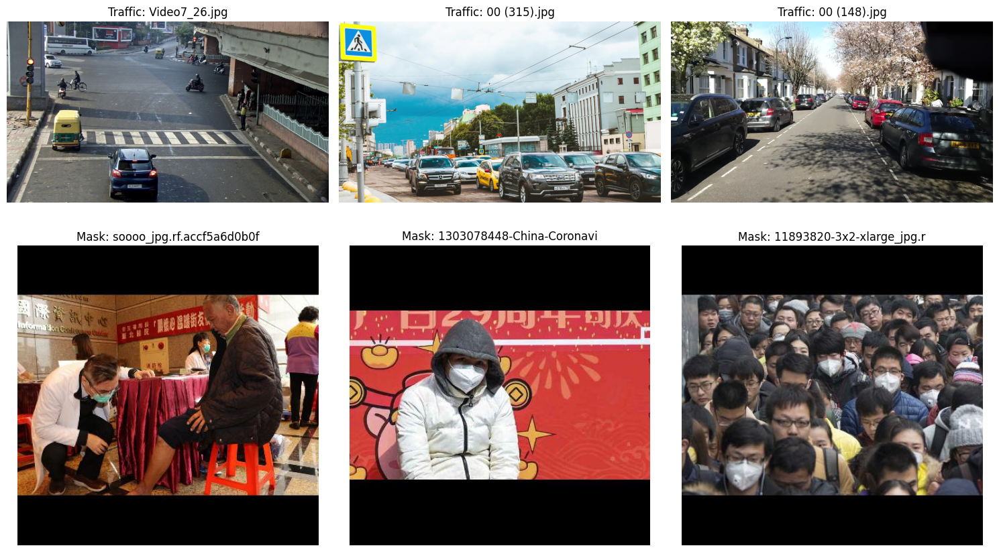

In [ ]:
#-- Show 3 random raw training images of each dataset. --#
plt.figure(figsize=(15, 9))
for row, ds in enumerate(DATASETS):
    files = list_images(ds, 'train')
    for col, file_name in enumerate(random.sample(files, min(3, len(files)))):
        plt.subplot(len(DATASETS), 3, row * 3 + col + 1)
        plt.imshow(Image.open(os.path.join(img_dir(ds, 'train'), file_name)))
        plt.title(f"{ds}: {file_name[:25]}")
        plt.axis('off')
plt.tight_layout()
plt.show()

# Part B: Exploratory Data Analysis (EDA). #

Every EDA step below is run for both datasets, so I can compare them.

## 2.1 Load All Annotations into Tables. ##

Each line of a YOLO label file is `class x_center y_center width height`, where the four box values are normalised to the range 0-1. I read every label file into one DataFrame per dataset, so that all EDA steps use the same data.

In [ ]:
#-- Read all label files of a dataset into one DataFrame (one row = one bounding box). --#
def load_labels(ds):
    rows = []
    for split in SPLITS:
        for label_file in list_labels(ds, split):
            with open(os.path.join(lbl_dir(ds, split), label_file)) as fh:
                for line in fh:
                    parts = line.split()
                    if len(parts) == 5:
                        rows.append((split, label_file, int(parts[0]), *map(float, parts[1:])))
    df = pd.DataFrame(rows, columns=['split', 'file', 'cls', 'x', 'y', 'w', 'h'])
    df['area'] = df['w'] * df['h']      #-- normalised box area (fraction of the whole image) --#
    return df

label_dfs = {ds: load_labels(ds) for ds in DATASETS}
for ds, df in label_dfs.items():
    print(f"{ds}: {len(df)} bounding boxes in {df['file'].nunique()} label files")
label_dfs['Traffic'].head()

Traffic: 11134 bounding boxes in 916 label files
Mask: 940 bounding boxes in 147 label files


,split,file,cls,x,y,w,h,area
0,train,00 (10).txt,2,0.543893,0.609375,0.041985,0.041667,0.001749
1,train,00 (10).txt,5,0.332061,0.346354,0.129771,0.182292,0.023656
2,train,00 (10).txt,5,0.568702,0.479167,0.351145,0.427083,0.149968
3,train,00 (100).txt,0,0.471484,0.884954,0.207552,0.228241,0.047372
4,train,00 (100).txt,0,0.721745,0.862963,0.255990,0.256481,0.065657


## 2.2 Check Class Distribution. ##

===== Traffic =====
split    train   val  total
class_0   4116  1061   5177
class_1    479   174    653
class_2   1149   161   1310
class_3   1598   271   1869
class_4   1072    94   1166
class_5    305   110    415
class_6    435   109    544
Most frequent class : class_0 (5177 boxes)
Least frequent class: class_5 (415 boxes)
Imbalance ratio     : 12.5 : 1



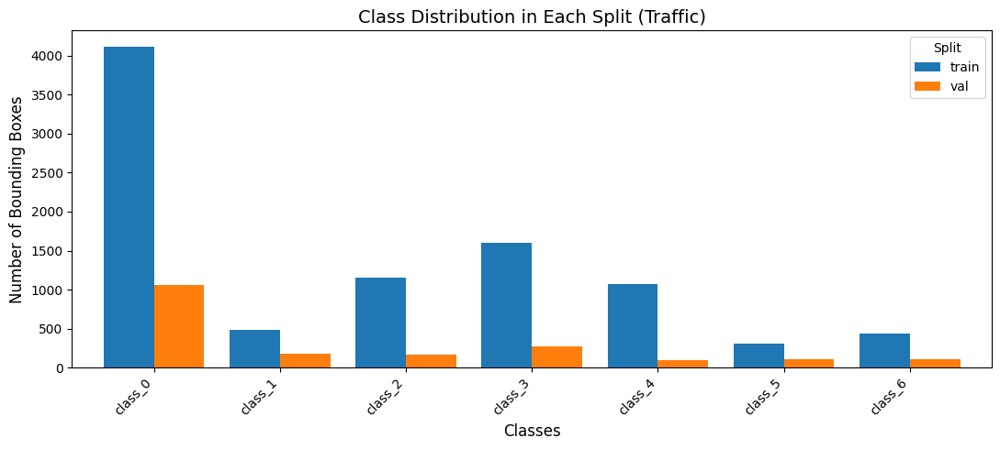

===== Mask =====
split    test  train  val  total
mask       91    561  140    792
no-mask     5    123   20    148
Most frequent class : mask (792 boxes)
Least frequent class: no-mask (148 boxes)
Imbalance ratio     : 5.4 : 1



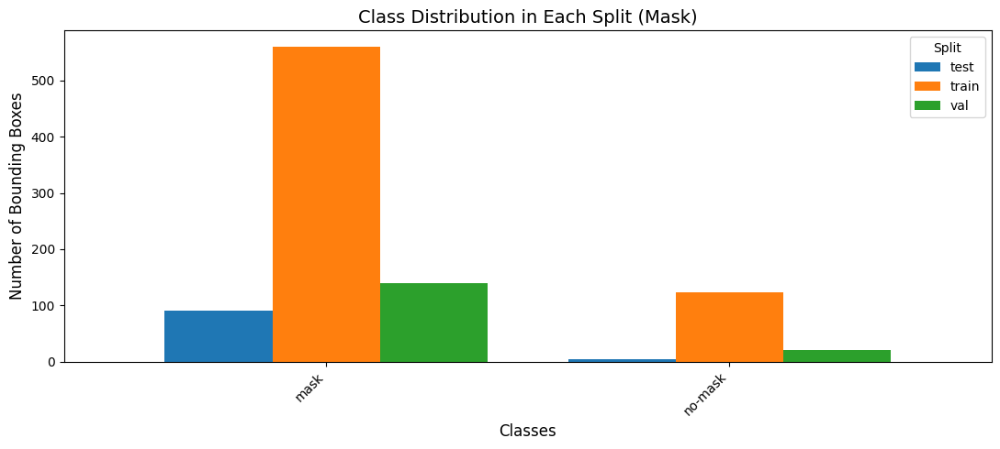

In [ ]:
#-- Count the bounding boxes of each class in each split, and plot them. --#
for ds in DATASETS:
    df, names = label_dfs[ds], DATASETS[ds]['names']
    counts = df.groupby(['cls', 'split']).size().unstack(fill_value=0).reindex(range(len(names)), fill_value=0)
    counts.index = names
    counts['total'] = counts.sum(axis=1)
    print(f"===== {ds} =====")
    print(counts)

    #-- Imbalance ratio = most frequent class / least frequent class. --#
    nonzero = counts['total'][counts['total'] > 0]
    print(f"Most frequent class : {nonzero.idxmax()} ({nonzero.max()} boxes)")
    print(f"Least frequent class: {nonzero.idxmin()} ({nonzero.min()} boxes)")
    print(f"Imbalance ratio     : {nonzero.max() / nonzero.min():.1f} : 1\n")

    counts.drop(columns='total').plot(kind='bar', figsize=(11, 5), width=0.8)
    plt.xlabel('Classes', fontsize=12)
    plt.ylabel('Number of Bounding Boxes', fontsize=12)
    plt.title(f'Class Distribution in Each Split ({ds})', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Split')
    plt.tight_layout()
    plt.show()

## 2.3 Check Image Dimension and Colour Channel. ##

In [ ]:
#-- Check the image size and colour mode of (up to) 200 images from each split of each dataset. --#
for ds in DATASETS:
    size_counter, mode_counter = Counter(), Counter()
    for split in SPLITS:
        files = list_images(ds, split)
        for file_name in random.sample(files, min(200, len(files))):
            with Image.open(os.path.join(img_dir(ds, split), file_name)) as img:
                size_counter[img.size] += 1       #-- (width, height) --#
                mode_counter[img.mode] += 1       #-- RGB / RGBA / L ... --#
    print(f"===== {ds} =====")
    print("Image sizes (width, height) -> number of sampled images:")
    for size, count in size_counter.most_common(5):
        print(f"  {size}: {count}")
    print(f"Colour modes: {dict(mode_counter)}\n")

===== Traffic =====
Image sizes (width, height) -> number of sampled images:
  (1920, 1080): 124
  (960, 540): 123
  (1080, 1920): 51
  (3840, 2160): 51
  (612, 408): 6
Colour modes: {'RGB': 462, 'RGBA': 122, 'P': 1}

===== Mask =====
Image sizes (width, height) -> number of sampled images:
  (416, 416): 72
  (416, 415): 61
  (415, 416): 13
  (415, 415): 1
Colour modes: {'RGB': 147}



## 2.4 Check Number of Objects per Image. ##

===== Traffic =====
       count   mean   std  min   25%   50%   75%   max
split                                                 
train  732.0  12.51  9.98  1.0  4.00  10.0  20.0  71.0
val    184.0  10.76  8.32  1.0  4.75   7.0  16.0  29.0
train: 6 images have no objects / no label file
val: 1 images have no objects / no label file

===== Mask =====
       count  mean    std  min  25%  50%  75%    max
split                                               
test    15.0  6.40   9.91  1.0  1.5  3.0  6.5   40.0
train  104.0  6.58  11.39  1.0  2.0  4.0  8.0  113.0
val     28.0  5.71   6.48  1.0  3.0  4.0  6.0   34.0
train: 0 images have no objects / no label file
val: 0 images have no objects / no label file
test: 0 images have no objects / no label file



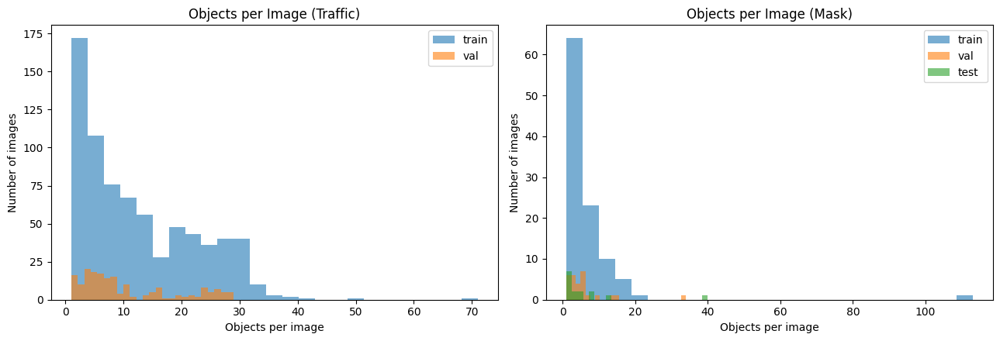

In [ ]:
#-- Number of boxes in each image, the images with no object, and a histogram. --#
fig, axes = plt.subplots(1, len(DATASETS), figsize=(13, 4.5))
for ax, ds in zip(axes, DATASETS):
    df = label_dfs[ds]
    objects_per_image = df.groupby(['split', 'file']).size().rename('objects').reset_index()
    print(f"===== {ds} =====")
    print(objects_per_image.groupby('split')['objects'].describe().round(2))
    for split in labelled_splits(ds):
        labelled = set(objects_per_image[objects_per_image['split'] == split]['file'].str.replace('.txt', '', regex=False))
        image_stems = set(os.path.splitext(f)[0] for f in list_images(ds, split))
        print(f"{split}: {len(image_stems - labelled)} images have no objects / no label file")
        ax.hist(objects_per_image[objects_per_image['split'] == split]['objects'], bins=25, alpha=0.6, label=split)
    ax.set_xlabel('Objects per image')
    ax.set_ylabel('Number of images')
    ax.set_title(f'Objects per Image ({ds})')
    ax.legend()
    print()
plt.tight_layout()
plt.show()

## 2.5 Check Bounding Box Size. ##

Small objects are the hardest to detect, so I check how large the boxes are compared with the whole image.

Traffic: small (<0.1% of image) = 17.4%, medium (0.1-1%) = 41.0%, large (>=1%) = 41.7%
Mask: small (<0.1% of image) = 8.5%, medium (0.1-1%) = 48.6%, large (>=1%) = 42.9%


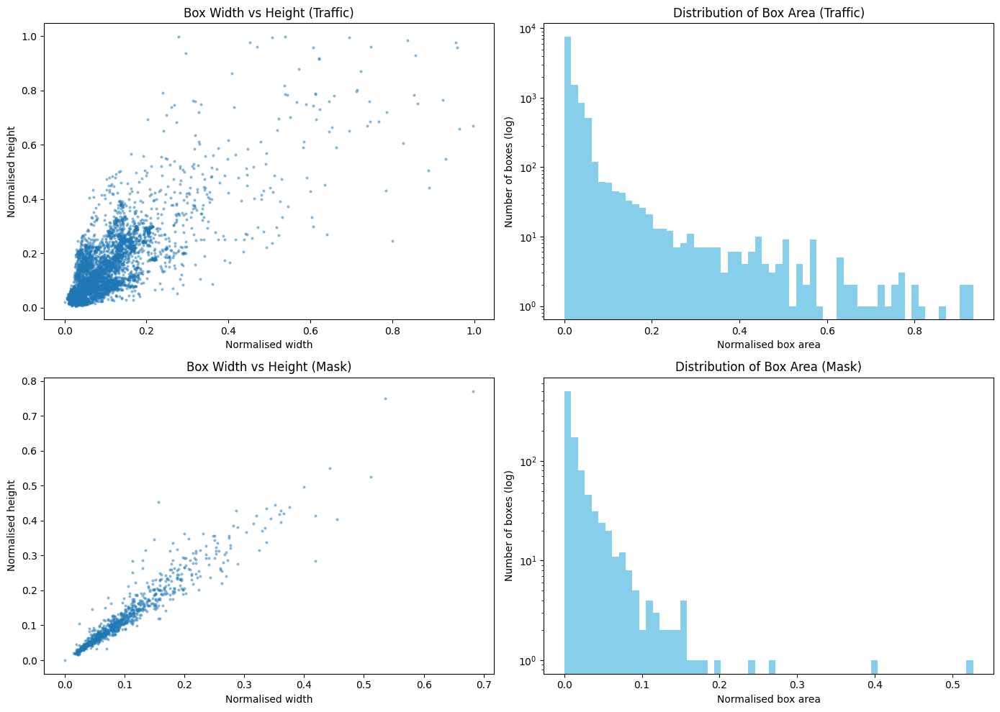

In [ ]:
#-- Percentage of small / medium / large boxes, then box width vs height and the area distribution. --#
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 5 * len(DATASETS)))
for row, ds in enumerate(DATASETS):
    df = label_dfs[ds]
    small = (df['area'] < 0.001).mean() * 100
    medium = ((df['area'] >= 0.001) & (df['area'] < 0.01)).mean() * 100
    large = (df['area'] >= 0.01).mean() * 100
    print(f"{ds}: small (<0.1% of image) = {small:.1f}%, medium (0.1-1%) = {medium:.1f}%, large (>=1%) = {large:.1f}%")

    plot_df = df.sample(min(5000, len(df)), random_state=42)
    axes[row, 0].scatter(plot_df['w'], plot_df['h'], s=4, alpha=0.4)
    axes[row, 0].set_xlabel('Normalised width')
    axes[row, 0].set_ylabel('Normalised height')
    axes[row, 0].set_title(f'Box Width vs Height ({ds})')
    axes[row, 1].hist(df['area'], bins=60, color='skyblue')
    axes[row, 1].set_yscale('log')
    axes[row, 1].set_xlabel('Normalised box area')
    axes[row, 1].set_ylabel('Number of boxes (log)')
    axes[row, 1].set_title(f'Distribution of Box Area ({ds})')
plt.tight_layout()
plt.show()

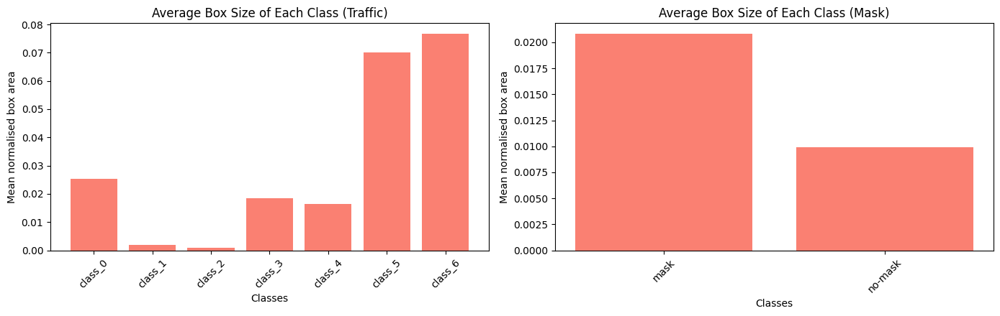

In [ ]:
#-- Average box area of each class (which classes are the smallest objects). --#
fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 4.5))
for ax, ds in zip(axes, DATASETS):
    names = DATASETS[ds]['names']
    mean_area = label_dfs[ds].groupby('cls')['area'].mean().reindex(range(len(names)))
    ax.bar(names, mean_area.values, color='salmon')
    ax.set_xlabel('Classes')
    ax.set_ylabel('Mean normalised box area')
    ax.set_title(f'Average Box Size of Each Class ({ds})')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 2.6 Check Label Quality. ##

Before training I check that the labels are valid: matching image/label names, coordinates inside 0-1, and valid class ids.

In [ ]:
#-- Label quality checks for both datasets. --#
for ds in DATASETS:
    df, num_classes = label_dfs[ds], DATASETS[ds]['nc']
    print(f"===== {ds} =====")
    #-- 1. Every label file should have an image with the same name (and the other way around). --#
    for split in labelled_splits(ds):
        image_stems = set(os.path.splitext(f)[0] for f in list_images(ds, split))
        label_stems = set(os.path.splitext(f)[0] for f in list_labels(ds, split))
        print(f"{split}: labels without image = {len(label_stems - image_stems)}, images without label = {len(image_stems - label_stems)}")
    #-- 2. Coordinates must be inside 0-1. --#
    coords = df[['x', 'y', 'w', 'h']]
    print(f"Boxes with coordinates outside [0, 1]: {((coords < 0) | (coords > 1)).any(axis=1).sum()}")
    #-- 3. Boxes with zero width or height. --#
    print(f"Boxes with zero width/height: {((df['w'] <= 0) | (df['h'] <= 0)).sum()}")
    #-- 4. Class ids must be between 0 and nc-1. --#
    print(f"Boxes with invalid class id: {((df['cls'] < 0) | (df['cls'] >= num_classes)).sum()}")
    #-- 5. Exact duplicate boxes in the same file. --#
    print(f"Duplicate boxes: {df.duplicated(subset=['split', 'file', 'cls', 'x', 'y', 'w', 'h']).sum()}")
    #-- 6. The same image name in two splits would leak data between train and evaluation. --#
    names_per_split = {s: set(os.path.splitext(f)[0] for f in list_images(ds, s)) for s in SPLITS}
    print(f"Images shared by train and the evaluation split: {len(names_per_split['train'] & names_per_split[DATASETS[ds]['eval_split']])}")
    #-- 7. Traffic images are named like Video9_8.jpg (frame 8 of video 9). If frames of the same video are in both --#
    #--    train and the evaluation split, the frames are almost identical and the scores can be too optimistic. --#
    if ds == 'Traffic':
        video_of = lambda stem: stem.rsplit('_', 1)[0]
        train_videos = set(video_of(s) for s in names_per_split['train'])
        eval_videos = set(video_of(s) for s in names_per_split[DATASETS[ds]['eval_split']])
        print(f"Videos in train: {len(train_videos)}, videos in evaluation split: {len(eval_videos)}, videos in both: {len(train_videos & eval_videos)}")
    print()

===== Traffic =====
train: labels without image = 0, images without label = 0
val: labels without image = 0, images without label = 0
Boxes with coordinates outside [0, 1]: 0
Boxes with zero width/height: 1
Boxes with invalid class id: 0
Duplicate boxes: 0
Images shared by train and the evaluation split: 0
Videos in train: 415, videos in evaluation split: 158, videos in both: 2

===== Mask =====
train: labels without image = 0, images without label = 0
val: labels without image = 0, images without label = 0
test: labels without image = 0, images without label = 0
Boxes with coordinates outside [0, 1]: 0
Boxes with zero width/height: 1
Boxes with invalid class id: 0
Duplicate boxes: 0
Images shared by train and the evaluation split: 0



## 2.7 Visualise Annotated Images. ##

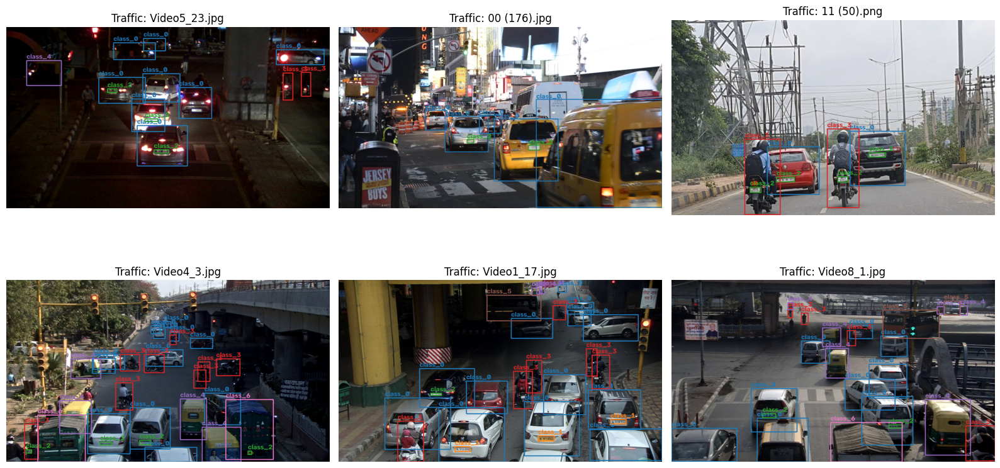

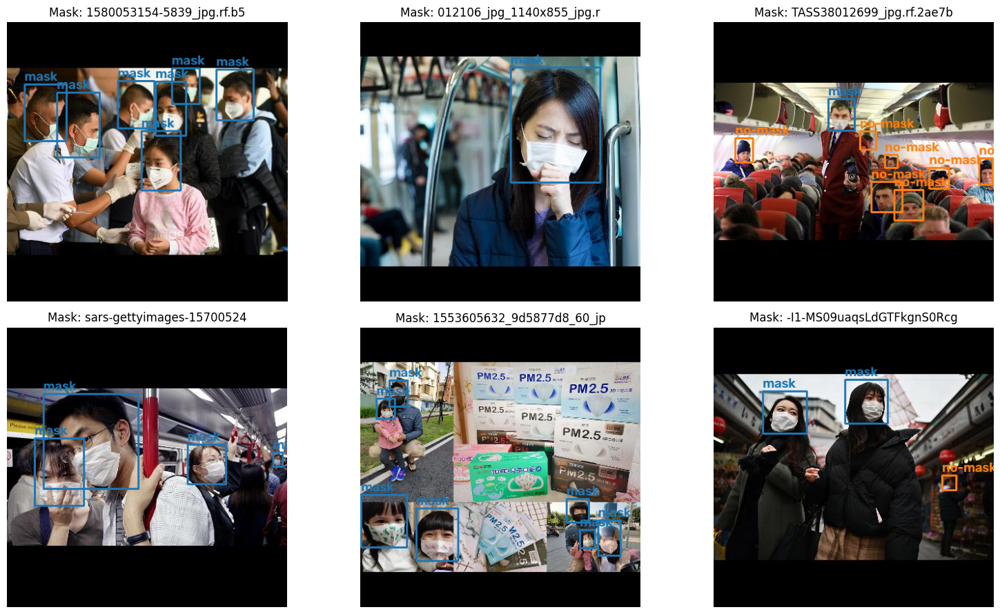

In [ ]:
#-- Draw the ground-truth boxes on random training images of both datasets. --#
palette = plt.cm.tab10(np.linspace(0, 1, 10))[:, :3] * 255      #-- one colour per class id (cycled) --#

def draw_boxes(ds, split, file_name):
    img = cv2.cvtColor(cv2.imread(os.path.join(img_dir(ds, split), file_name)), cv2.COLOR_BGR2RGB)
    height, width = img.shape[:2]
    thickness = max(2, width // 400)
    label_path = os.path.join(lbl_dir(ds, split), os.path.splitext(file_name)[0] + '.txt')
    if os.path.exists(label_path):
        with open(label_path) as fh:
            for line in fh:
                parts = line.split()
                if len(parts) != 5:
                    continue
                c = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])
                #-- Convert the normalised YOLO format back to pixel corners. --#
                x1, y1 = int((xc - w / 2) * width), int((yc - h / 2) * height)
                x2, y2 = int((xc + w / 2) * width), int((yc + h / 2) * height)
                color = tuple(int(v) for v in palette[c % 10])
                cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)
                cv2.putText(img, DATASETS[ds]['names'][c], (x1, max(y1 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, thickness / 3, color, thickness)
    return img

for ds in DATASETS:
    files = list_images(ds, 'train')
    plt.figure(figsize=(16, 9))
    for i, file_name in enumerate(random.sample(files, min(6, len(files)))):
        plt.subplot(2, 3, i + 1)
        plt.imshow(draw_boxes(ds, 'train', file_name))
        plt.title(f"{ds}: {file_name[:25]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Part C: Pretrained Model Evaluation. #

I load a pretrained YOLO model (`yolo26n.pt`, trained on the COCO dataset with 80 classes) and evaluate it **without any training** on my datasets. This gives the baseline that the fine-tuned models are compared with.

> **Evaluation split.** The lab asks for the test set. The **Mask** dataset has a labelled test set, so it is used. The **Traffic** test images have no label files (section 1.4), so mAP, precision and recall cannot be calculated on them. For Traffic I use the **validation split** (a labelled split that is not used to update the weights) and use the test images only for visual predictions.

## 3.1 Load the Pretrained Model. ##

In [ ]:
#-- Import YOLO. --#
from ultralytics import YOLO

#-- Load the pretrained weights (downloaded automatically on the first run). --#
PRETRAINED_WEIGHTS = 'yolo26n.pt'
pretrained_model = YOLO(PRETRAINED_WEIGHTS)

#-- The pretrained model was trained on COCO, so it predicts the 80 COCO classes. --#
print(f"Number of classes in the pretrained model: {len(pretrained_model.names)}")
print(f"First 10 COCO classes: {[pretrained_model.names[i] for i in range(10)]}")
for ds in DATASETS:
    print(f"Classes in the {ds} dataset: {DATASETS[ds]['names']}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Number of classes in the pretrained model: 80
First 10 COCO classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']
Classes in the Traffic dataset: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4', 'class_5', 'class_6']
Classes in the Mask dataset: ['mask', 'no-mask']


## 3.2 Evaluate the Pretrained Model. ##

I define helper functions once and reuse them for every model, so that all models are evaluated in exactly the same way.

In [ ]:
#-- Helper function: evaluate a model on one split of one dataset and return the four required metrics. --#
def evaluate_model(model, ds, split, name):
    metrics = model.val(data=DATASETS[ds]['yaml'], split=split, imgsz=640, batch=16,
                        plots=False, verbose=False,
                        project=RUNS_DIR, name=name, exist_ok=True)
    scores = {
        'mAP50': float(metrics.box.map50),       #-- mean AP at IoU 0.50 --#
        'mAP50-95': float(metrics.box.map),      #-- mean AP averaged over IoU 0.50 to 0.95 --#
        'Precision': float(metrics.box.mp),      #-- mean precision over classes --#
        'Recall': float(metrics.box.mr),         #-- mean recall over classes --#
    }
    return scores, metrics

#-- Helper function: AP50-95 of each class that appears in the evaluation split. --#
def per_class_ap(metrics):
    return {int(c): float(ap) for c, ap in zip(metrics.box.ap_class_index, metrics.box.all_ap.mean(axis=1))}

In [ ]:
#-- Evaluate the pretrained model on the evaluation split of both datasets. --#
pretrained_results = {}
for ds in DATASETS:
    scores, metrics = evaluate_model(pretrained_model, ds, DATASETS[ds]['eval_split'], f'{ds}_pretrained')
    pretrained_results[ds] = (scores, metrics)
    print(f"\n{ds} - pretrained model ({DATASETS[ds]['eval_split']} split):")
    for key, value in scores.items():
        print(f"  {key}: {value:.4f}")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1822.4±505.5 MB/s, size: 114.6 KB)
val: Scanning /content/Lab06_Data/labels/val... 185 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 1.8Kit/s 0.1s
val: New cache created: /content/Lab06_Data/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.0it/s 3.0s
                   all        185       1980      0.184      0.148      0.127     0.0732
Speed: 1.1ms preprocess, 6.4ms inference, 0.0ms loss, 2.5ms postprocess per image

Traffic - pretrained model (val split):
  mAP50: 0.1275
  mAP50-95: 0.0732
  Precision: 0.1844
  Recall: 0.1480
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradi

## 3.3 Visual Predictions of the Pretrained Model. ##

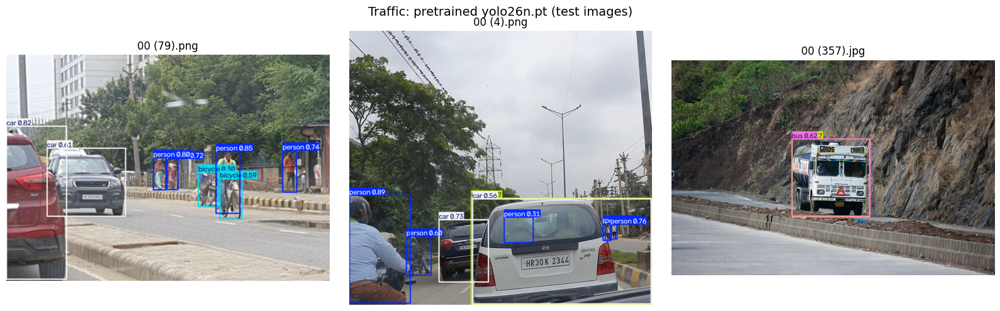

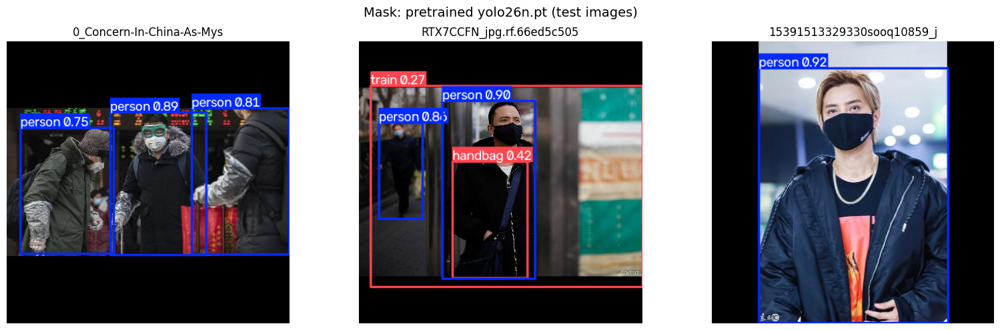

In [ ]:
#-- Helper function: predict on some images and show the result. --#
def show_predictions(model, image_paths, title):
    results = model.predict(source=image_paths, imgsz=640, conf=0.25, verbose=False)
    plt.figure(figsize=(16, 5))
    for i, result in enumerate(results):
        plt.subplot(1, len(results), i + 1)
        plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))   #-- result.plot() returns a BGR image --#
        plt.title(os.path.basename(image_paths[i])[:25])
        plt.axis('off')
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

#-- The same 3 images per dataset are used for every model: test images if available, otherwise validation images. --#
demo_paths = {}
for ds in DATASETS:
    demo_split = 'test' if len(list_images(ds, 'test')) > 0 else 'val'
    demo_files = random.sample(list_images(ds, demo_split), min(3, len(list_images(ds, demo_split))))
    demo_paths[ds] = [os.path.join(img_dir(ds, demo_split), f) for f in demo_files]
    show_predictions(pretrained_model, demo_paths[ds], f'{ds}: pretrained {PRETRAINED_WEIGHTS} ({demo_split} images)')

# Part D: Fine-Tuning the Model. #

Fine-tuning continues the training of the pretrained model on my own data. As in the lab, I use `epochs=30`, `imgsz=640` and `freeze=10`. `freeze=10` freezes the first 10 layers (the backbone that already learned general edges, textures and shapes) and only updates the remaining layers (the later feature layers and the detection head) so they adapt to my classes. One model is trained for each dataset.

## 4.1 Train the Models. ##

In [ ]:
#-- Helper function: fine-tune a model on a dataset and return the folder of the run. --#
def train_model(ds, weights, run_name, **overrides):
    config = dict(
        data=DATASETS[ds]['yaml'],   #-- data.yaml created in Part A --#
        epochs=30,                   #-- number of passes over the training set (value from the lab) --#
        imgsz=640,                   #-- input image size --#
        freeze=10,                   #-- freeze the first 10 layers (value from the lab) --#
        batch=16,                    #-- images per batch --#
        seed=42,                     #-- reproducible results --#
        project=RUNS_DIR,
        name=run_name,
        exist_ok=True,
        plots=True,                  #-- save the training curves and confusion matrix --#
    )
    config.update(overrides)         #-- change some values for the later experiments --#
    model = YOLO(weights)            #-- always start from a fresh copy of the pretrained weights --#
    start = time.time()
    model.train(**config)
    return str(model.trainer.save_dir), time.time() - start

#-- Fine-tune yolo26n on both datasets (baseline required by the lab). --#
ft_dirs, train_times = {}, {}
for ds in DATASETS:
    ft_dirs[ds], train_times[(ds, PRETRAINED_WEIGHTS)] = train_model(ds, PRETRAINED_WEIGHTS, f'{ds}_finetune')
    print(f"{ds}: training finished in {train_times[(ds, PRETRAINED_WEIGHTS)] / 60:.1f} minutes -> {ft_dirs[ds]}")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Lab06_Data/traffic_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Traffic_finetune, nbs=64, nms=None, opset=None, optimiz

## 4.2 Training Curves. ##

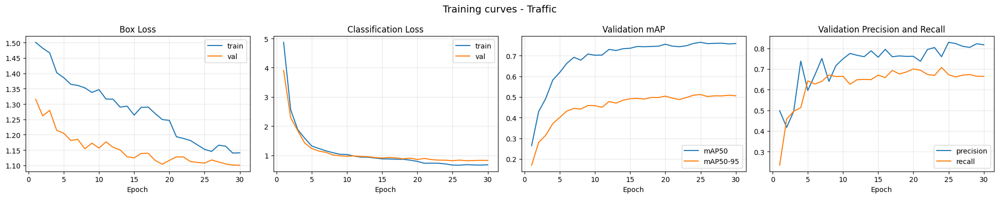

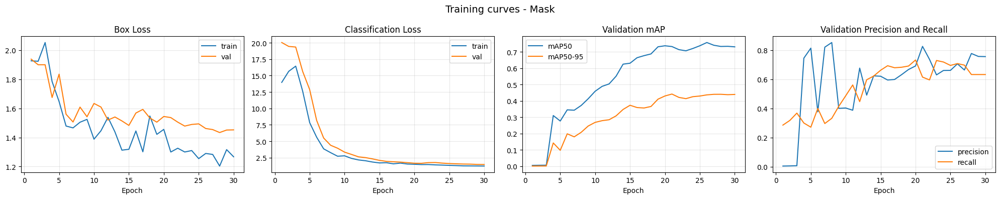

In [ ]:
#-- Plot the losses and the validation metrics of every training run. --#
for ds in DATASETS:
    #-- Read the per-epoch log (column names contain extra spaces, so strip them). --#
    results_df = pd.read_csv(os.path.join(ft_dirs[ds], 'results.csv'))
    results_df.columns = results_df.columns.str.strip()

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    axes[0].plot(results_df['epoch'], results_df['train/box_loss'], label='train')
    axes[0].plot(results_df['epoch'], results_df['val/box_loss'], label='val')
    axes[0].set_title('Box Loss')
    axes[1].plot(results_df['epoch'], results_df['train/cls_loss'], label='train')
    axes[1].plot(results_df['epoch'], results_df['val/cls_loss'], label='val')
    axes[1].set_title('Classification Loss')
    axes[2].plot(results_df['epoch'], results_df['metrics/mAP50(B)'], label='mAP50')
    axes[2].plot(results_df['epoch'], results_df['metrics/mAP50-95(B)'], label='mAP50-95')
    axes[2].set_title('Validation mAP')
    axes[3].plot(results_df['epoch'], results_df['metrics/precision(B)'], label='precision')
    axes[3].plot(results_df['epoch'], results_df['metrics/recall(B)'], label='recall')
    axes[3].set_title('Validation Precision and Recall')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.suptitle(f'Training curves - {ds}', fontsize=14)
    plt.tight_layout()
    plt.show()

## 4.3 Save the Best Weights to Google Drive. ##

In [ ]:
#-- best.pt = weights of the epoch with the highest validation fitness (mAP-based). --#
#-- Copy them to the Lab06 folder on Google Drive so they are not lost when Colab disconnects. --#
for ds in DATASETS:
    best_path = os.path.join(ft_dirs[ds], 'weights', 'best.pt')
    target_path = os.path.join(drive_models_dir, f'{ds.lower()}_yolo26n_finetuned.pt')
    shutil.copy(best_path, target_path)
    print(f"{ds}: {best_path} -> {target_path}")

Traffic: /content/runs/Traffic_finetune/weights/best.pt -> /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/models/traffic_yolo26n_finetuned.pt
Mask: /content/runs/Mask_finetune/weights/best.pt -> /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/models/mask_yolo26n_finetuned.pt


# Part E: Evaluation and Comparison. #

## 5.1 Evaluate the Fine-Tuned Models. ##

In [ ]:
#-- Load the best fine-tuned weights and evaluate on the SAME split as the pretrained model. --#
finetuned_results = {}
for ds in DATASETS:
    model = YOLO(os.path.join(ft_dirs[ds], 'weights', 'best.pt'))
    scores, metrics = evaluate_model(model, ds, DATASETS[ds]['eval_split'], f'{ds}_finetuned')
    finetuned_results[ds] = (scores, metrics)
    print(f"\n{ds} - fine-tuned model ({DATASETS[ds]['eval_split']} split):")
    for key, value in scores.items():
        print(f"  {key}: {value:.4f}")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3057.9±1515.8 MB/s, size: 157.5 KB)
val: Scanning /content/Lab06_Data/labels/val.cache... 185 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 3.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.0it/s 3.0s
                   all        185       1980      0.826      0.671      0.765      0.511
Speed: 1.1ms preprocess, 4.4ms inference, 0.0ms loss, 2.4ms postprocess per image

Traffic - fine-tuned model (val split):
  mAP50: 0.7646
  mAP50-95: 0.5114
  Precision: 0.8263
  Recall: 0.6711
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0

## 5.2 Results Table. ##

In [ ]:
#-- Build the comparison table (pretrained vs fine-tuned) for both datasets. --#
tables = []
for ds in DATASETS:
    table = pd.DataFrame({'Pretrained': pretrained_results[ds][0], 'Fine-tuned': finetuned_results[ds][0]})
    table['Change (abs)'] = table['Fine-tuned'] - table['Pretrained']
    #-- Relative change in percent (avoid dividing by zero). --#
    table['Change (%)'] = np.where(table['Pretrained'] > 0, table['Change (abs)'] / table['Pretrained'] * 100, np.nan)
    table.insert(0, 'Dataset', ds)
    tables.append(table)
comparison_df = pd.concat(tables)
comparison_df.round(4)

,Dataset,Pretrained,Fine-tuned,Change (abs),Change (%)
mAP50,Traffic,0.1275,0.7646,0.6371,499.6494
mAP50-95,Traffic,0.0732,0.5114,0.4382,598.5458
Precision,Traffic,0.1844,0.8263,0.6419,348.1851
Recall,Traffic,0.1480,0.6711,0.5230,353.3057
mAP50,Mask,0.0176,0.7325,0.7149,4069.8838
mAP50-95,Mask,0.0049,0.3937,0.3888,7969.8649
Precision,Mask,0.5422,0.9059,0.3637,67.0897
Recall,Mask,0.0714,0.6314,0.5599,783.9172


## 5.3 Comparison Chart. ##

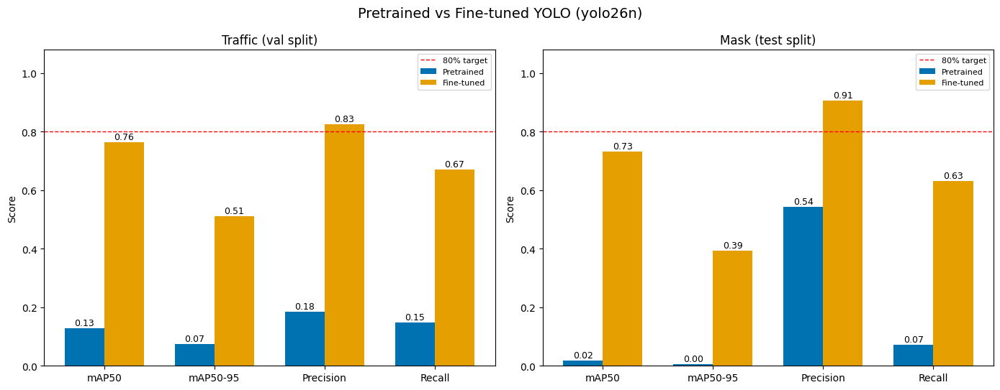

In [ ]:
#-- Grouped bar chart of the four metrics for each dataset. --#
metric_names = ['mAP50', 'mAP50-95', 'Precision', 'Recall']
x = np.arange(len(metric_names))
width = 0.36
fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 5.5))
for ax, ds in zip(axes, DATASETS):
    pre = [pretrained_results[ds][0][m] for m in metric_names]
    fine = [finetuned_results[ds][0][m] for m in metric_names]
    bars1 = ax.bar(x - width / 2, pre, width, label='Pretrained', color='#0072B2')
    bars2 = ax.bar(x + width / 2, fine, width, label='Fine-tuned', color='#E69F00')
    for bars in (bars1, bars2):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{bar.get_height():.2f}', ha='center', fontsize=9)
    ax.axhline(0.80, color='red', linestyle='--', linewidth=1, label='80% target')
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel('Score')
    ax.set_title(f'{ds} ({DATASETS[ds]["eval_split"]} split)')
    ax.legend(loc='upper right', fontsize=8)
plt.suptitle('Pretrained vs Fine-tuned YOLO (yolo26n)', fontsize=14)
plt.tight_layout()
plt.show()

## 5.4 Per-Class Performance. ##

The average metrics hide which classes improved. Here I compare the AP (mAP50-95) of every class.

===== Traffic =====
  Class  Pretrained AP50-95  Fine-tuned AP50-95  Change
class_0              0.0001              0.7512  0.7511
class_1              0.0000              0.4458  0.4458
class_2              0.0000              0.2409  0.2409
class_3              0.0798              0.6263  0.5464
class_4              0.0000              0.2802  0.2802
class_5              0.4277              0.6263  0.1986
class_6              0.0048              0.6092  0.6044


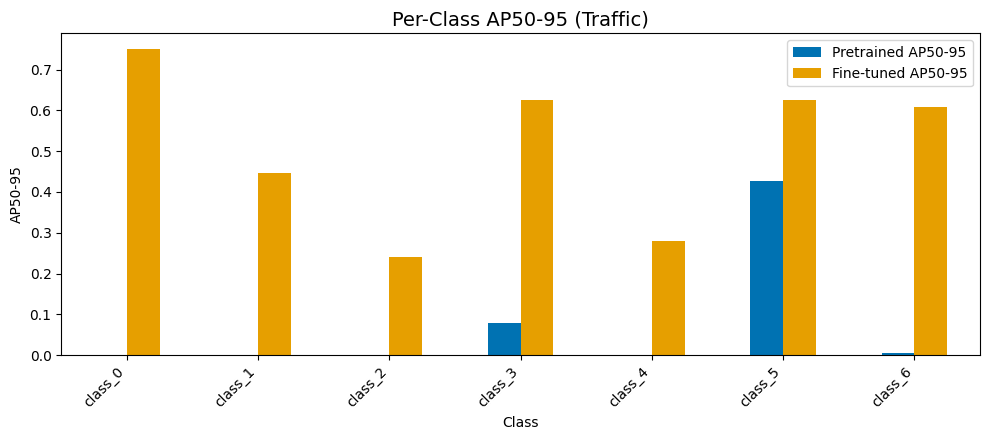

===== Mask =====
  Class  Pretrained AP50-95  Fine-tuned AP50-95  Change
   mask              0.0098              0.5325  0.5228
no-mask              0.0000              0.2549  0.2549


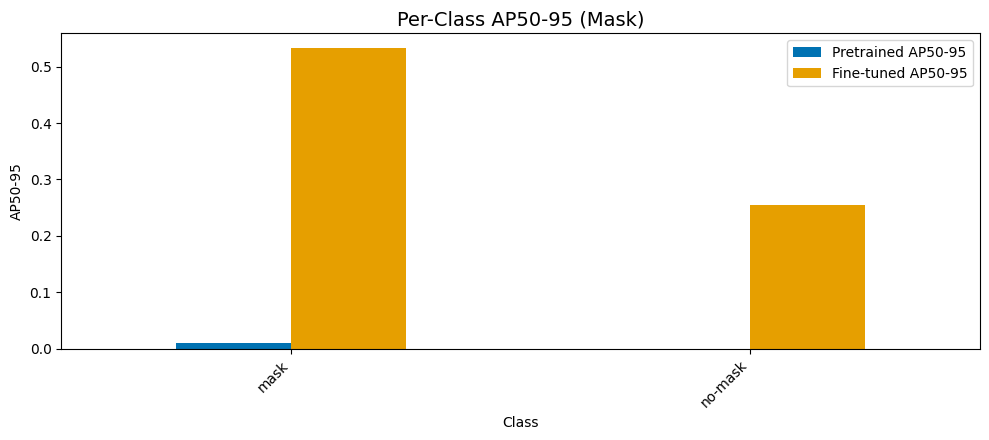

In [ ]:
#-- AP50-95 of each class, pretrained vs fine-tuned (0 if the model never detected that class correctly). --#
for ds in DATASETS:
    names = DATASETS[ds]['names']
    pre_ap = per_class_ap(pretrained_results[ds][1])
    ft_ap = per_class_ap(finetuned_results[ds][1])
    per_class_df = pd.DataFrame({
        'Class': names,
        'Pretrained AP50-95': [pre_ap.get(i, 0.0) for i in range(len(names))],
        'Fine-tuned AP50-95': [ft_ap.get(i, 0.0) for i in range(len(names))],
    })
    per_class_df['Change'] = per_class_df['Fine-tuned AP50-95'] - per_class_df['Pretrained AP50-95']
    print(f"===== {ds} =====")
    print(per_class_df.round(4).to_string(index=False))

    per_class_df.set_index('Class')[['Pretrained AP50-95', 'Fine-tuned AP50-95']].plot(kind='bar', figsize=(10, 4.5), color=['#0072B2', '#E69F00'])
    plt.ylabel('AP50-95')
    plt.title(f'Per-Class AP50-95 ({ds})', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

## 5.5 Confusion Matrix of the Fine-Tuned Models. ##

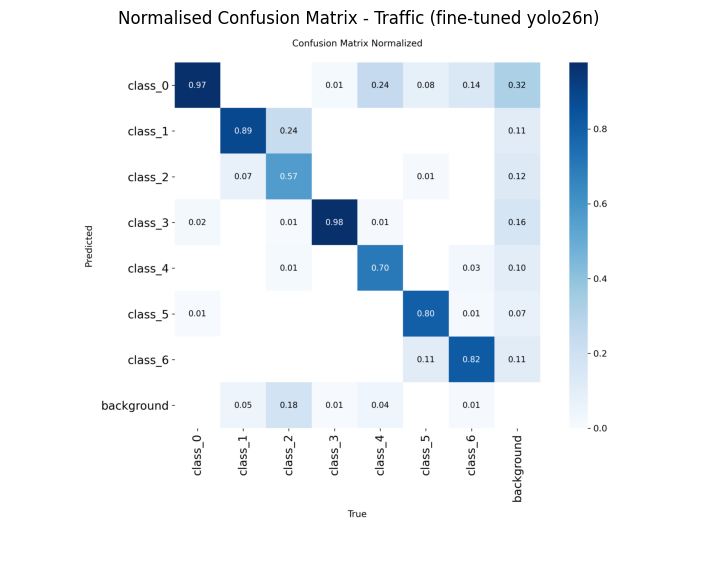

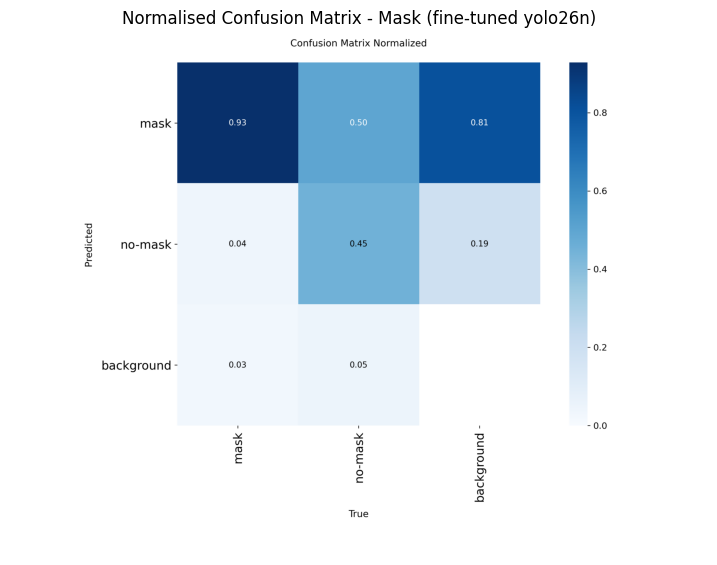

In [ ]:
#-- YOLO saves the confusion matrix of the final validation run in the training folder. --#
for ds in DATASETS:
    confusion_path = os.path.join(ft_dirs[ds], 'confusion_matrix_normalized.png')
    if os.path.exists(confusion_path):
        plt.figure(figsize=(9, 7))
        plt.imshow(Image.open(confusion_path))
        plt.axis('off')
        plt.title(f'Normalised Confusion Matrix - {ds} (fine-tuned yolo26n)')
        plt.show()
    else:
        print(f"{ds}: confusion matrix image not found in {ft_dirs[ds]}")

## 5.6 Visual Comparison on the Same Images. ##

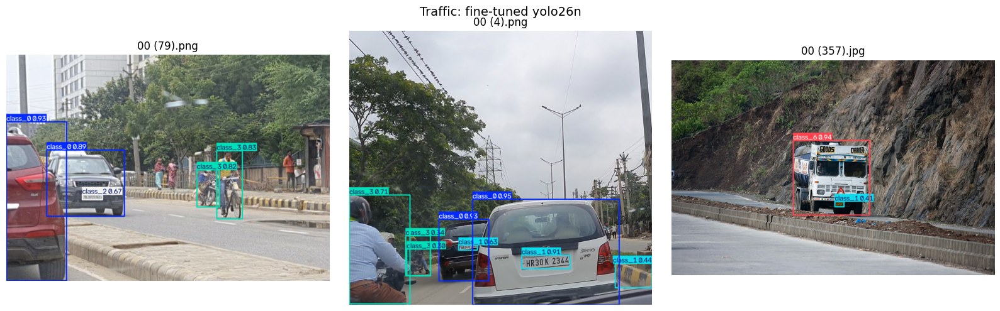

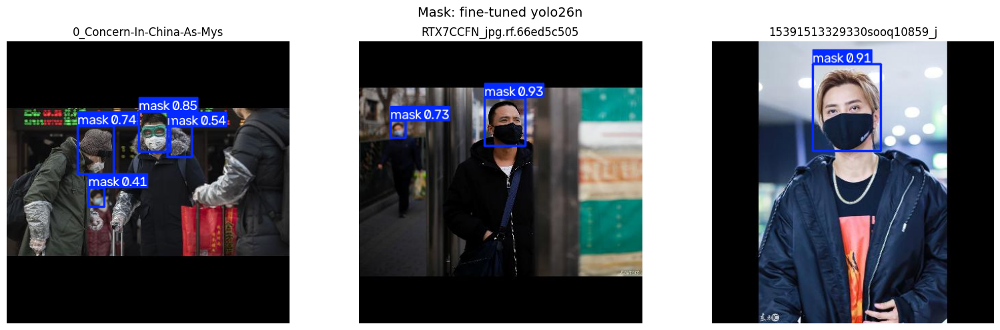

In [ ]:
#-- Same images as Part C, now predicted with the fine-tuned models. --#
for ds in DATASETS:
    model = YOLO(os.path.join(ft_dirs[ds], 'weights', 'best.pt'))
    show_predictions(model, demo_paths[ds], f'{ds}: fine-tuned yolo26n')

## 5.7 Check the 80% Target for the Baseline Fine-Tuned Models. ##

In [ ]:
#-- Helper function: compare the four metrics with the target (80%) and show a pass/fail table. --#
TARGET = 0.80
def target_table(scores_by_dataset):
    rows = []
    for ds, scores in scores_by_dataset.items():
        for metric, value in scores.items():
            rows.append({'Dataset': ds, 'Metric': metric, 'Score': round(value, 4), 'Target': TARGET,
                         'Met?': 'YES' if value >= TARGET else 'NO'})
    return pd.DataFrame(rows)

baseline_scores = {ds: finetuned_results[ds][0] for ds in DATASETS}
target_table(baseline_scores)

,Dataset,Metric,Score,Target,Met?
0,Traffic,mAP50,0.7646,0.8,NO
1,Traffic,mAP50-95,0.5114,0.8,NO
2,Traffic,Precision,0.8263,0.8,YES
3,Traffic,Recall,0.6711,0.8,NO
4,Mask,mAP50,0.7325,0.8,NO
5,Mask,mAP50-95,0.3937,0.8,NO
6,Mask,Precision,0.9059,0.8,YES
7,Mask,Recall,0.6314,0.8,NO


# Part F: Model Selection and Optimisation (Target: 80%). #

The baseline (`yolo26n`, 30 epochs, `freeze=10`) may not reach 80% on every metric. In this part I try to find the best model in a fair way:

1. **Compare model sizes** (`yolo26n`, `yolo26s`, `yolo26m`) with the same training settings. Larger models can learn more detail but train slower and can overfit small datasets.
2. **Select** the model with the highest **mAP50-95 on the validation split**. The test split is not used for selection, so the final test result is not biased.
3. **Optimise** the selected model once more with a longer schedule (`epochs=100`, `freeze=0`, `patience=20`) and keep it only if it improves the validation mAP50-95.
4. **Report** the final scores on the evaluation split and check them against the 80% target.

> **Important.** 80% is a target, not something I can force. mAP50-95 needs very accurate box positions and is normally much lower than mAP50, so it may stay below 80% even for a good model. The tables below report honestly which metrics reach the target.

## 6.1 Compare Model Sizes. ##

In [ ]:
#-- Candidate models. yolo26n is already trained in Part D, so only the larger models are trained here. --#
CANDIDATES = ['yolo26n.pt', 'yolo26s.pt', 'yolo26m.pt']

trained_dirs = {ds: {PRETRAINED_WEIGHTS: ft_dirs[ds]} for ds in DATASETS}
selection_rows = []
for ds in DATASETS:
    for weights in CANDIDATES:
        #-- Train the candidate (skip yolo26n: already trained). --#
        if weights not in trained_dirs[ds]:
            run_name = f"{ds}_{weights.replace('.pt', '')}"
            trained_dirs[ds][weights], train_times[(ds, weights)] = train_model(ds, weights, run_name)
        #-- Evaluate on the VALIDATION split (used for model selection). --#
        best_path = os.path.join(trained_dirs[ds][weights], 'weights', 'best.pt')
        scores, _ = evaluate_model(YOLO(best_path), ds, 'val', f"{ds}_{weights.replace('.pt', '')}_select")
        selection_rows.append({'Dataset': ds, 'Model': weights.replace('.pt', ''), **scores,
                               'Train time (min)': train_times[(ds, weights)] / 60})

selection_df = pd.DataFrame(selection_rows)
selection_df.round(4)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2253.9±759.5 MB/s, size: 101.3 KB)
val: Scanning /content/Lab06_Data/labels/val.cache... 185 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 77.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.1it/s 2.9s
                   all        185       1980      0.826      0.671      0.765      0.511
Speed: 1.1ms preprocess, 4.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=Tr

,Dataset,Model,mAP50,mAP50-95,Precision,Recall,Train time (min)
0,Traffic,yolo26n,0.7646,0.5114,0.8263,0.6711,9.0194
1,Traffic,yolo26s,0.8422,0.5831,0.8172,0.7711,9.0471
2,Traffic,yolo26m,0.8461,0.6036,0.8350,0.7698,12.7293
3,Mask,yolo26n,0.7320,0.4417,0.8240,0.6159,1.3504
4,Mask,yolo26s,0.8256,0.5266,0.9542,0.6071,1.7003
5,Mask,yolo26m,0.8000,0.4818,0.7987,0.7300,3.9933


## 6.2 Model Comparison Chart. ##

In [ ]:
#-- Compare the model sizes on the validation split. --#
fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 5.5))
for ax, ds in zip(axes, DATASETS):
    sub = selection_df[selection_df['Dataset'] == ds].set_index('Model')[metric_names]
    sub.plot(kind='bar', ax=ax, width=0.8)
    ax.axhline(0.80, color='red', linestyle='--', linewidth=1)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Score (validation split)')
    ax.set_title(f'Model sizes - {ds}')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 6.3 Select the Best Model. ##

In [ ]:
#-- Best model of each dataset = highest mAP50-95 on the validation split. --#
best_model_name = {}
for ds in DATASETS:
    sub = selection_df[selection_df['Dataset'] == ds]
    best_row = sub.loc[sub['mAP50-95'].idxmax()]
    best_model_name[ds] = best_row['Model'] + '.pt'
    print(f"{ds}: best model = {best_row['Model']} (validation mAP50-95 = {best_row['mAP50-95']:.4f})")

## 6.4 Optimise the Selected Models. ##

One longer run per dataset: all layers are trained (`freeze=0`), 100 epochs, and early stopping (`patience=20`) stops the run if the validation fitness does not improve for 20 epochs.

In [36]:
#-- Longer training of the selected model of each dataset. --#
optimised_dirs = {}
for ds in DATASETS:
    weights = best_model_name[ds]
    optimised_dirs[ds], train_times[(ds, 'optimised')] = train_model(
        ds, weights, f"{ds}_optimised", epochs=100, freeze=0, patience=20)
    print(f"{ds}: optimised {weights} finished in {train_times[(ds, 'optimised')] / 60:.1f} minutes")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Lab06_Data/traffic_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Traffic_optimised, nbs=64, nms=None, opset=None, optimi

In [37]:
#-- Keep the optimised model only if it has a higher validation mAP50-95 than the selected model. --#
final_dirs, final_names = {}, {}
comparison_rows = []
for ds in DATASETS:
    selected_dir = trained_dirs[ds][best_model_name[ds]]
    selected_scores, _ = evaluate_model(YOLO(os.path.join(selected_dir, 'weights', 'best.pt')), ds, 'val', f'{ds}_selected_val')
    optimised_scores, _ = evaluate_model(YOLO(os.path.join(optimised_dirs[ds], 'weights', 'best.pt')), ds, 'val', f'{ds}_optimised_val')
    comparison_rows.append({'Dataset': ds, 'Model': f"{best_model_name[ds]} (30 epochs, freeze=10)", **selected_scores})
    comparison_rows.append({'Dataset': ds, 'Model': f"{best_model_name[ds]} (optimised)", **optimised_scores})
    if optimised_scores['mAP50-95'] > selected_scores['mAP50-95']:
        final_dirs[ds], final_names[ds] = optimised_dirs[ds], f"{best_model_name[ds]} (optimised)"
    else:
        final_dirs[ds], final_names[ds] = selected_dir, f"{best_model_name[ds]} (30 epochs, freeze=10)"
    print(f"{ds}: final model = {final_names[ds]}")
pd.DataFrame(comparison_rows).round(4)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,849 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2243.1±955.7 MB/s, size: 274.5 KB)
val: Scanning /content/Lab06_Data/labels/val.cache... 185 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 45.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.3it/s 5.1s
                   all        185       1980      0.835       0.77      0.846      0.604
Speed: 0.8ms preprocess, 20.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,849 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2562.4±1042.1 MB/s, size: 144.8 KB)
val: Scanning /content/Lab06_Data/labels/val.cache... 185 i

,Dataset,Model,mAP50,mAP50-95,Precision,Recall
0,Traffic,"yolo26m.pt (30 epochs, freeze=10)",0.8461,0.6036,0.8350,0.7698
1,Traffic,yolo26m.pt (optimised),0.8622,0.5971,0.8095,0.7911
2,Mask,"yolo26s.pt (30 epochs, freeze=10)",0.8256,0.5266,0.9542,0.6071
3,Mask,yolo26s.pt (optimised),0.8776,0.5177,0.8445,0.8086


## 6.5 Final Evaluation and 80% Target Check. ##

The final models are evaluated once on the evaluation split (the **test** split for Mask, the **validation** split for Traffic because its test images have no labels).

In [38]:
#-- Final evaluation of the final model of each dataset, and copy the weights to Google Drive. --#
final_scores, final_metrics = {}, {}
for ds in DATASETS:
    final_best = os.path.join(final_dirs[ds], 'weights', 'best.pt')
    final_scores[ds], final_metrics[ds] = evaluate_model(YOLO(final_best), ds, DATASETS[ds]['eval_split'], f'{ds}_final')
    shutil.copy(final_best, os.path.join(drive_models_dir, f'{ds.lower()}_final_model.pt'))
    print(f"{ds}: {final_names[ds]} on the {DATASETS[ds]['eval_split']} split")
    for key, value in final_scores[ds].items():
        print(f"  {key}: {value:.4f}")

#-- Pass / fail table against the 80% target. --#
target_table(final_scores)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,849 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2208.9±812.5 MB/s, size: 121.2 KB)
val: Scanning /content/Lab06_Data/labels/val.cache... 185 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 185/185 36.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.3it/s 5.3s
                   all        185       1980      0.835       0.77      0.846      0.604
Speed: 0.8ms preprocess, 21.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Traffic: yolo26m.pt (30 epochs, freeze=10) on the val split
  mAP50: 0.8461
  mAP50-95: 0.6036
  Precision: 0.8350
  Recall: 0.7698
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast imag

,Dataset,Metric,Score,Target,Met?
0,Traffic,mAP50,0.8461,0.8,YES
1,Traffic,mAP50-95,0.6036,0.8,NO
2,Traffic,Precision,0.8350,0.8,YES
3,Traffic,Recall,0.7698,0.8,NO
4,Mask,mAP50,0.8420,0.8,YES
5,Mask,mAP50-95,0.4819,0.8,NO
6,Mask,Precision,0.6922,0.8,NO
7,Mask,Recall,0.9523,0.8,YES


In [ ]:
#-- Compare: pretrained -> baseline fine-tuned -> final model (same evaluation split). --#
fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 5.5))
for ax, ds in zip(axes, DATASETS):
    stages = pd.DataFrame({
        'Pretrained': pretrained_results[ds][0],
        'Fine-tuned yolo26n': finetuned_results[ds][0],
        'Final model': final_scores[ds],
    }).loc[metric_names]
    stages.plot(kind='bar', ax=ax, width=0.8, color=['#0072B2', '#E69F00', '#009E73'])
    ax.axhline(0.80, color='red', linestyle='--', linewidth=1)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Score')
    ax.set_title(f'{ds} ({DATASETS[ds]["eval_split"]} split): {final_names[ds]}', fontsize=10)
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 6.6 Final Predictions. ##

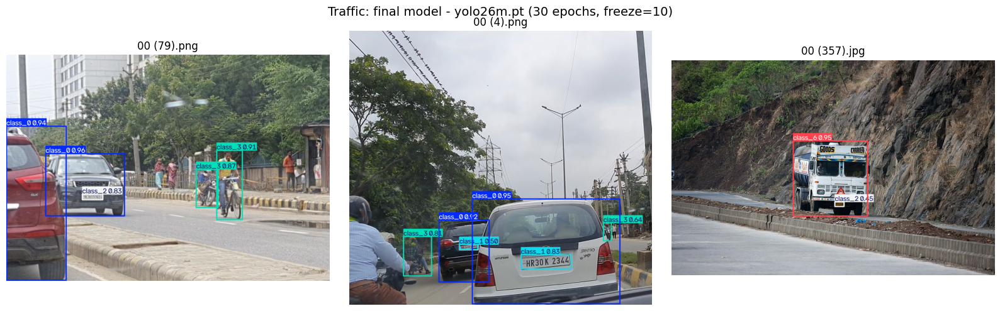

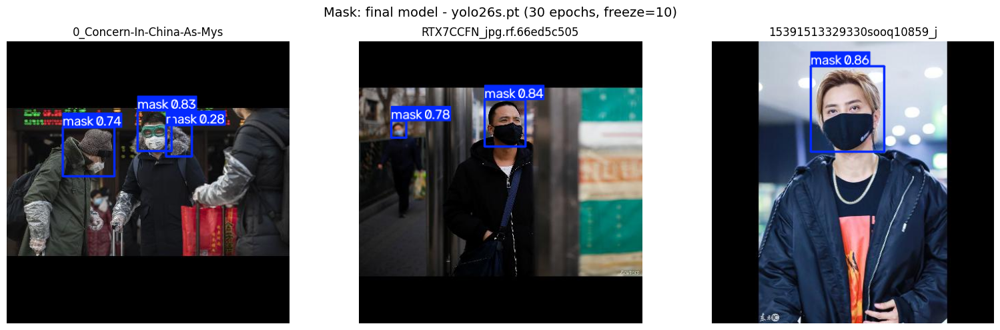

In [40]:
#-- Predictions of the final model of each dataset on the same demo images. --#
for ds in DATASETS:
    show_predictions(YOLO(os.path.join(final_dirs[ds], 'weights', 'best.pt')), demo_paths[ds], f'{ds}: final model - {final_names[ds]}')

In [41]:
#-- Automatic summary (numbers come directly from the evaluation above). --#
for ds in DATASETS:
    met = [m for m in metric_names if final_scores[ds][m] >= TARGET]
    not_met = [m for m in metric_names if final_scores[ds][m] < TARGET]
    print(f"{ds}: final model = {final_names[ds]}")
    print(f"   metrics >= 80%: {met if met else 'none'}")
    print(f"   metrics  < 80%: {not_met if not_met else 'none'}")

Traffic: final model = yolo26m.pt (30 epochs, freeze=10)
   metrics >= 80%: ['mAP50', 'Precision']
   metrics  < 80%: ['mAP50-95', 'Recall']
Mask: final model = yolo26s.pt (30 epochs, freeze=10)
   metrics >= 80%: ['mAP50', 'Recall']
   metrics  < 80%: ['mAP50-95', 'Precision']


## 6.7 Export the Results for the Report. ##

All tables used in the report are saved as CSV files in the Lab06 folder on Google Drive, so I can copy the numbers into the Word report.

In [42]:
#-- Save the result tables (baseline comparison, model sizes, final models) to Google Drive. --#
comparison_df.round(4).to_csv(os.path.join(drive_lab_dir, 'results_pretrained_vs_finetuned.csv'))
selection_df.round(4).to_csv(os.path.join(drive_lab_dir, 'results_model_sizes.csv'), index=False)
target_table(final_scores).to_csv(os.path.join(drive_lab_dir, 'results_final_models.csv'), index=False)
summary_df.to_csv(os.path.join(drive_lab_dir, 'results_dataset_summary.csv'), index=False)
print("Saved 4 CSV files to:", drive_lab_dir)

Saved 4 CSV files to: /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab06 - Object Detection/


# Part G: Conclusions. #

**What I did.** I loaded two YOLO-format datasets from Google Drive (Traffic and Mask-Wearing), analysed them, evaluated the pretrained `yolo26n.pt` without training, fine-tuned it with `freeze=10` for 30 epochs, compared model sizes (`yolo26n`, `yolo26s`, `yolo26m`), optimised the selected model, and checked mAP50, mAP50-95, precision and recall against the 80% target.

**What I learned about YOLO datasets.**
* A YOLO dataset keeps images and labels in parallel folders. Each image has one `.txt` file with one line per object: `class x_center y_center width height`, all normalised to 0-1, so the same label stays valid when the image is resized to 640 x 640.
* Two datasets can use different folder layouts (`images/train` vs `train/images`). YOLO only needs the image path to contain `/images/` so that it can find `/labels/`, and a `data.yaml` file to describe the splits and class names.
* A split without label files (the Traffic test images) can only be used for visual prediction, not for mAP, precision or recall. Checking this during EDA, before training, avoided a wrong evaluation.
* Class ids start from 0 in every dataset, so two datasets cannot be merged by copying label files; the ids would have to be re-mapped. This is why I trained one model per dataset.

**What I learned from the EDA.**
* The class distribution, number of objects per image and box size explain results that the final metrics cannot explain alone: rare classes and very small objects are usually the weakest in detection.
* Validating labels (matching names, coordinates inside 0-1, valid class ids, no shared images between train and evaluation) is important, because wrong labels or data leakage directly change the metrics.

**What I learned about pretrained models and fine-tuning.**
* A model pretrained on COCO has already learned general visual features. However, it predicts the 80 COCO class ids, which do not match the class ids of my datasets, so a direct evaluation on my labels is a weak baseline. Fine-tuning adapts the detection head to my own classes.
* Freezing the first 10 layers keeps the general features, trains faster and reduces overfitting on small datasets, while the remaining layers learn dataset-specific patterns. Unfreezing everything (`freeze=0`) can give a better fit but needs more epochs and more data.
* mAP50 is more forgiving than mAP50-95, because mAP50-95 also needs very accurate box positions. A model can have a high mAP50 but a much lower mAP50-95 when its boxes are only roughly aligned, which is common for small objects. For this reason an 80% target is much harder to reach for mAP50-95 than for mAP50, precision or recall.
* Bigger models are not always better: they train slower and can overfit small datasets. Selecting the model on the validation split and reporting the test split only once keeps the final result honest.

**Limitations and next steps.**
* The Traffic dataset has no labelled test split, so its final result is reported on the validation split, which was also used by YOLO to choose `best.pt` and by me to choose the model size. Its scores can therefore be slightly optimistic. A labelled test split would give a fairer estimate.
* The Traffic images are frames taken from videos (names like `Video9_8`). If frames of the same video are in both the training and the evaluation split, the frames are almost identical and the scores are optimistic (see the check in section 2.6). Splitting by video would give a more honest estimate.
* The Mask dataset is small, so its scores can change noticeably with a different random seed. Repeating the training with several seeds would show how stable the result is.
* Possible improvements: more labelled data for rare classes, stronger augmentation, a larger image size for small objects, and a longer training schedule.